In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json
import sqlite3

In [ ]:
# df_grouped = pd.read_csv("grouped_price_history_data_forecasting_model.csv")
df_merged = pd.read_csv("merged_price_history_data_forecasting_model.csv")

In [3]:
df_merged_yes = df_merged[df_merged['outcome'] == 'Yes']

df_merged_yes

,t,p,market_id,event_name,outcome,category
2212,1774114258,0.4450,7653310878196227531065116514963407925189973393...,US forces enter Iran by April 30?,Yes,Politics
2213,1774114847,0.4450,7653310878196227531065116514963407925189973393...,US forces enter Iran by April 30?,Yes,Politics
2214,1774115445,0.4450,7653310878196227531065116514963407925189973393...,US forces enter Iran by April 30?,Yes,Politics
2215,1774116053,0.4450,7653310878196227531065116514963407925189973393...,US forces enter Iran by April 30?,Yes,Politics
2216,1774116639,0.4450,7653310878196227531065116514963407925189973393...,US forces enter Iran by April 30?,Yes,Politics
...,...,...,...,...,...,...
232248,1775352645,0.0005,8987142112220602042707907390683801535921406989...,Will FC Barcelona win on 2026-04-04?,Yes,Sports
232249,1775353240,0.0005,8987142112220602042707907390683801535921406989...,Will FC Barcelona win on 2026-04-04?,Yes,Sports
232250,1775353839,0.0005,8987142112220602042707907390683801535921406989...,Will FC Barcelona win on 2026-04-04?,Yes,Sports
232251,1775355041,0.0005,8987142112220602042707907390683801535921406989...,Will FC Barcelona win on 2026-04-04?,Yes,Sports


In [ ]:
# Create a copy of the un-grouped merged data using df_merged_yes
df_resample = df_merged_yes.copy()

# Ensure datetime is set and set it as the index for resampling
df_resample['datetime'] = pd.to_datetime(df_resample['t'], unit='s')
df_resample.set_index('datetime', inplace=True)

# Group by our keys and resample to 30-minute intervals, taking the mean of the prices
df_30m = df_resample.groupby(['event_name', 'category', 'outcome']).resample('30min')['p'].mean().reset_index()

# Drop intervals that had no data (NaNs)
df_30m = df_30m.dropna(subset=['p'])

# Convert datetime back to Unix timestamps for consistency
# Using a map to safely process the datetime to a unix seconds timestamp
df_30m['t'] = df_30m['datetime'].apply(lambda x: int(x.timestamp()))


df_30m = df_30m.rename(columns={
    'event_name': 'Event_name',
    't': 'timestamp',
    'p': 'price'
})

print(f"Total records after 30-minute resampling: {len(df_30m)}")
display(df_30m.head(10))

Total records after 30-minute resampling: 42971


,Event_name,category,outcome,datetime,price,timestamp
0,Arizona Wildcats vs. Michigan Wolverines,Sports,Yes,2026-03-29 21:30:00,0.4625,1774819800
1,Arizona Wildcats vs. Michigan Wolverines,Sports,Yes,2026-03-29 22:00:00,0.4300,1774821600
2,Arizona Wildcats vs. Michigan Wolverines,Sports,Yes,2026-03-29 22:30:00,0.5150,1774823400
3,Arizona Wildcats vs. Michigan Wolverines,Sports,Yes,2026-03-29 23:00:00,0.5150,1774825200
4,Arizona Wildcats vs. Michigan Wolverines,Sports,Yes,2026-03-29 23:30:00,0.5625,1774827000
5,Arizona Wildcats vs. Michigan Wolverines,Sports,Yes,2026-03-30 00:00:00,0.5150,1774828800
6,Arizona Wildcats vs. Michigan Wolverines,Sports,Yes,2026-03-30 00:30:00,0.5150,1774830600
7,Arizona Wildcats vs. Michigan Wolverines,Sports,Yes,2026-03-30 01:00:00,0.5150,1774832400
8,Arizona Wildcats vs. Michigan Wolverines,Sports,Yes,2026-03-30 01:30:00,0.5150,1774834200
9,Arizona Wildcats vs. Michigan Wolverines,Sports,Yes,2026-03-30 02:00:00,0.5150,1774836000


/tmp/ipykernel_4019586/509940459.py:21: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


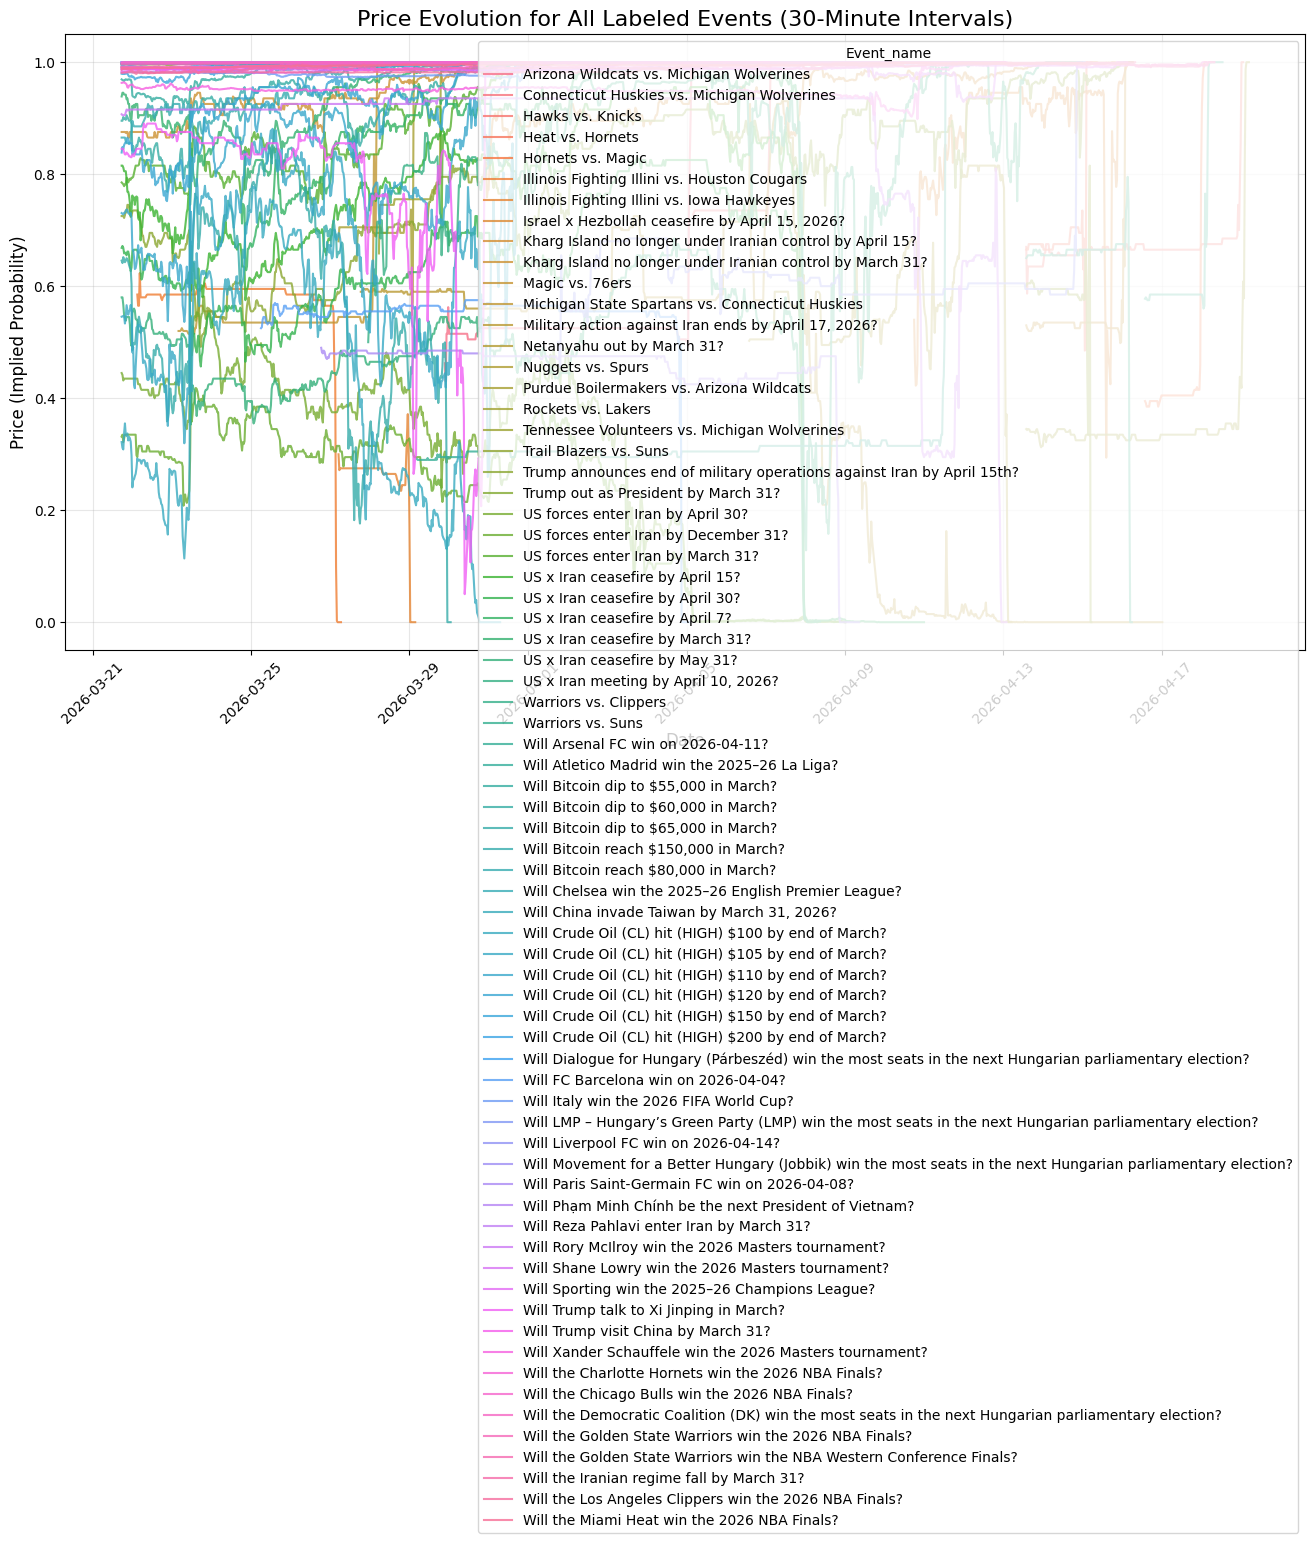

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(16, 8))

# Plot each event's price over time
sns.lineplot(data=df_30m, x='datetime', y='price', hue='Event_name', alpha=0.8, linewidth=1.5)

plt.title('Price Evolution for All Labeled Events (30-Minute Intervals)', fontsize=16)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Price (Implied Probability)', fontsize=12)

# # Place the legend outside the plot area to avoid cluttering if there are many events
# if df_30m['Event_name'].nunique() > 10:
#     plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize='small', title='Event Name')
# else:
#     plt.legend(title='Event Name')

plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Creating 8 lag features (4 hours total)...
Training shapes: X=(33928, 14), y=(33928,)
Testing shapes: X=(8483, 14), y=(8483,)
Training XGBoost Regressor...

--- Model Evaluation ---
RMSE: 0.0010
MAE:  0.0003

--- Top 10 Feature Importances ---


,Feature,Importance
4,price_lag_1,0.985764
6,price_lag_3,0.002849
8,price_lag_5,0.001819
3,category_Sports,0.001621
7,price_lag_4,0.001427
9,price_lag_6,0.001386
12,rolling_mean_4h,0.001310
5,price_lag_2,0.001091
10,price_lag_7,0.000837
11,price_lag_8,0.000670


/tmp/ipykernel_4019586/3925557980.py:88: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=importance.head(10), x='Importance', y='Feature', palette='viridis')


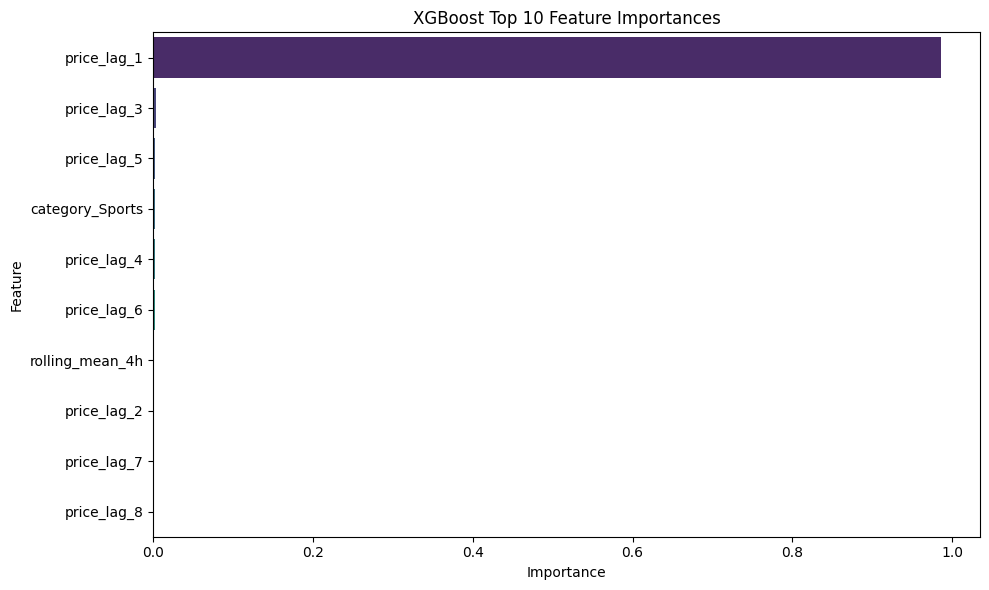

In [7]:
# !pip install xgboost scikit-learn

import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error
import matplotlib.pyplot as plt

# 1. Prepare copy of data and sort chronologically per event
df_ml = df_30m.copy()
df_ml = df_ml.sort_values(by=['Event_name', 'datetime'])

# 2. Encode the category column using One-Hot Encoding
df_ml = pd.get_dummies(df_ml, columns=['category'], drop_first=False)

# 3. Create 4-hour sliding window features 
# Since data is in 30-min intervals, 4 hours = 8 intervals
window_size = 8

print(f"Creating {window_size} lag features (4 hours total)...")
for i in range(1, window_size + 1):
    df_ml[f'price_lag_{i}'] = df_ml.groupby('Event_name')['price'].shift(i)

# Add rolling window statistics (mean and std) over the preceding 4 hours
df_ml['rolling_mean_4h'] = df_ml.groupby('Event_name')['price'].transform(
    lambda x: x.shift(1).rolling(window=window_size).mean()
)
df_ml['rolling_std_4h'] = df_ml.groupby('Event_name')['price'].transform(
    lambda x: x.shift(1).rolling(window=window_size).std()
)

# Drop rows with NaN values resulting from the shift (the first 4 hours of each event)
df_ml = df_ml.dropna().reset_index(drop=True)

# 4. Separate Features (X) and Target (y)
# Target is the current price. We predict it using the 4 hours of past prices.
exclude_cols = ['Event_name', 'outcome', 'timestamp', 'datetime', 't', 'price']
feature_cols = [c for c in df_ml.columns if c not in exclude_cols]

X = df_ml[feature_cols]
y = df_ml['price']

# 5. Temporal Train/Test Split (80/20)
# We avoid random shuffling to prevent data leakage from the future into the past
split_idx = int(len(df_ml) * 0.8)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

print(f"Training shapes: X={X_train.shape}, y={y_train.shape}")
print(f"Testing shapes: X={X_test.shape}, y={y_test.shape}")

# 6. Train XGBoost Regressor
# Values are bounded 0-1, so we could use a logistic objective or clip predictions
model = xgb.XGBRegressor(
    n_estimators=150,
    learning_rate=0.05,
    max_depth=5,
    random_state=42,
    objective='reg:squarederror'
)

print("Training XGBoost Regressor...")
model.fit(X_train, y_train)

# 7. Evaluate Model
preds = model.predict(X_test)
preds = np.clip(preds, 0, 1)  # Ensure probabilities stay between 0 and 1

rmse = np.sqrt(mean_squared_error(y_test, preds))
mae = mean_absolute_error(y_test, preds)

print("\n--- Model Evaluation ---")
print(f"RMSE: {rmse:.4f}")
print(f"MAE:  {mae:.4f}")

# 8. Feature Importances
importance = pd.DataFrame({
    'Feature': feature_cols, 
    'Importance': model.feature_importances_
}).sort_values(by='Importance', ascending=False)

print("\n--- Top 10 Feature Importances ---")
display(importance.head(10))

# Plot feature importances
plt.figure(figsize=(10, 6))
sns.barplot(data=importance.head(10), x='Importance', y='Feature', palette='viridis')
plt.title("XGBoost Top 10 Feature Importances")
plt.tight_layout()
plt.show()


Top 1 Event (Highest Min-Max Deviation: 0.0945): Will Xander Schauffele win the 2026 Masters tournament?

=== 4-Hour Forecast Metrics ===
RMSE (Root Mean Squared Error): 0.0367
MAE (Mean Absolute Error):      0.0322
Directional Accuracy:           50.0%



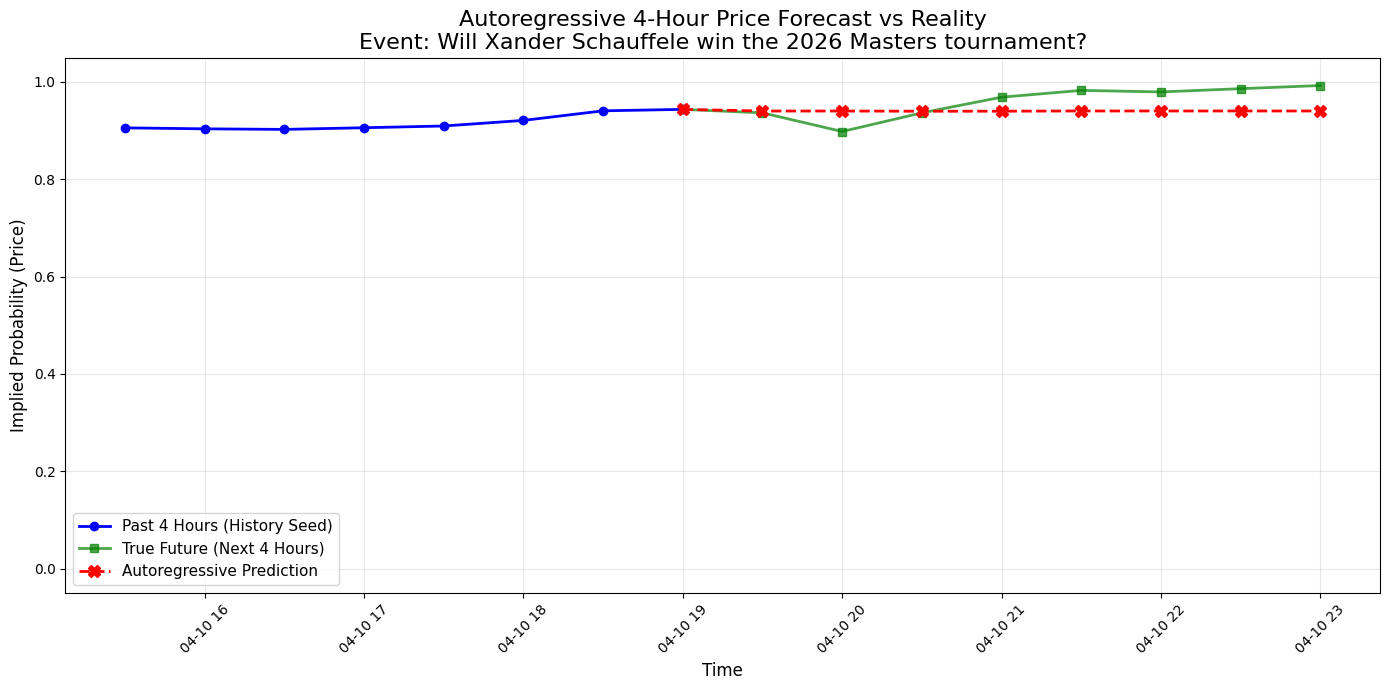


Top 2 Event (Highest Min-Max Deviation: 0.0080): Will the Golden State Warriors win the 2026 NBA Finals?

=== 4-Hour Forecast Metrics ===
RMSE (Root Mean Squared Error): 0.0043
MAE (Mean Absolute Error):      0.0038
Directional Accuracy:           25.0%



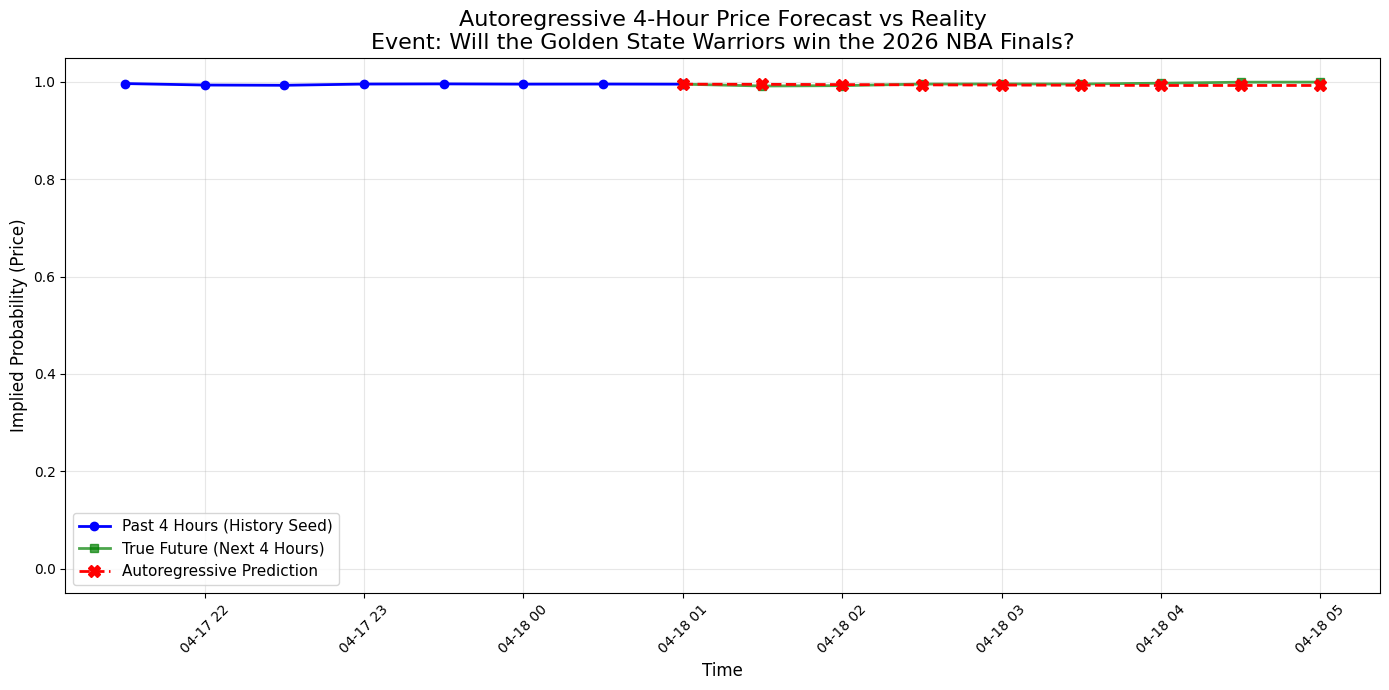


Top 3 Event (Highest Min-Max Deviation: 0.0070): Will the Charlotte Hornets win the 2026 NBA Finals?

=== 4-Hour Forecast Metrics ===
RMSE (Root Mean Squared Error): 0.0033
MAE (Mean Absolute Error):      0.0021
Directional Accuracy:           62.5%



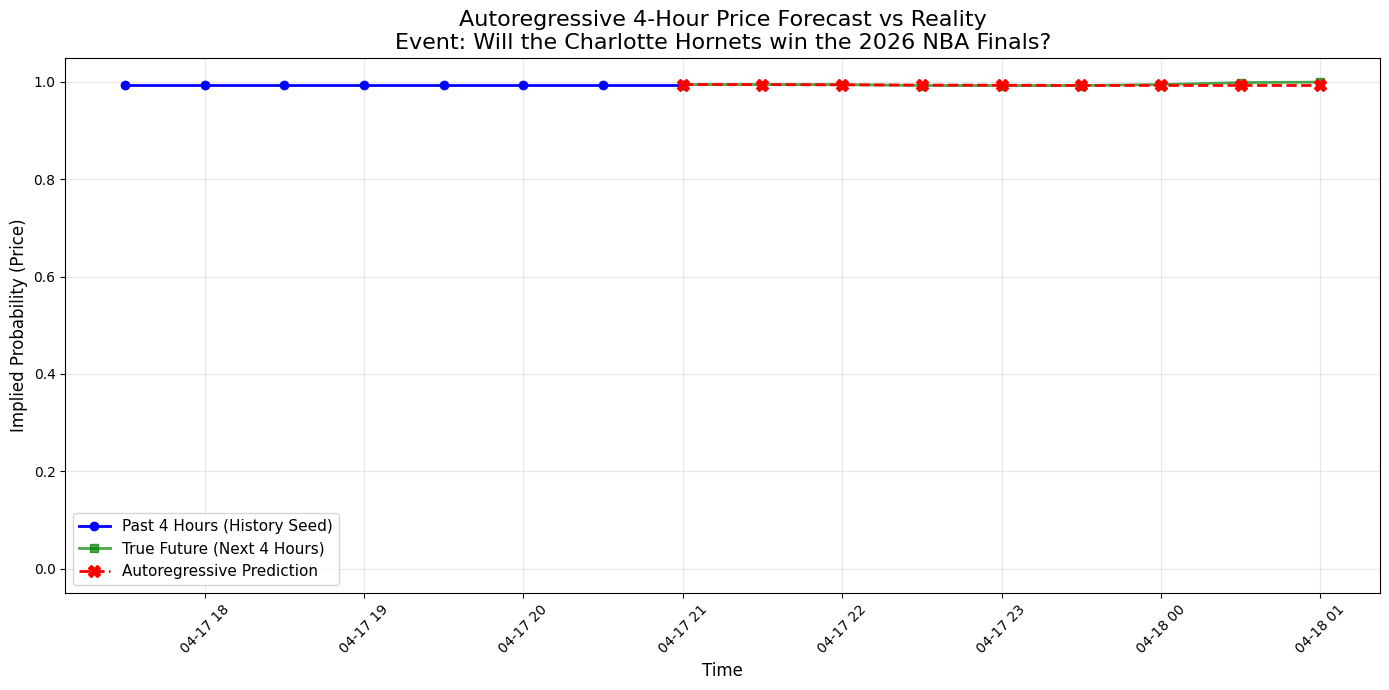


Top 4 Event (Highest Min-Max Deviation: 0.0055): Will the Golden State Warriors win the NBA Western Conference Finals?

=== 4-Hour Forecast Metrics ===
RMSE (Root Mean Squared Error): 0.0035
MAE (Mean Absolute Error):      0.0024
Directional Accuracy:           62.5%



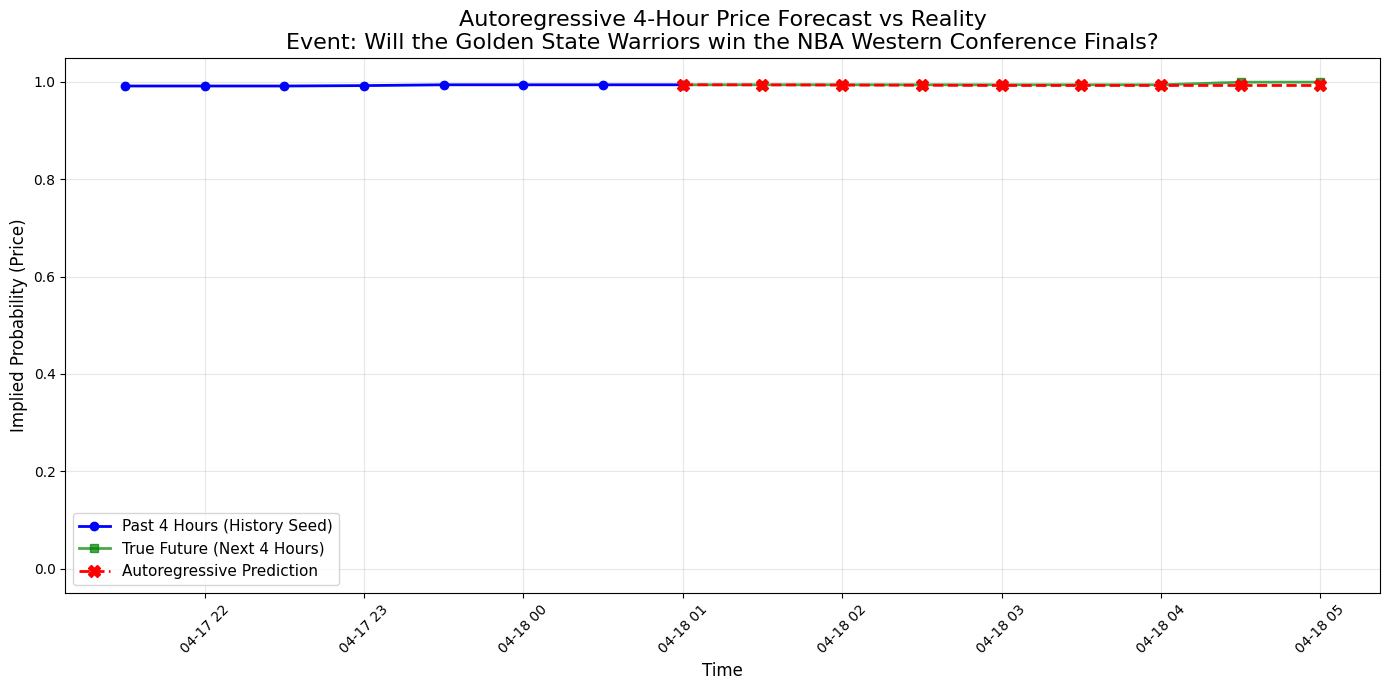


Top 5 Event (Highest Min-Max Deviation: 0.0053): Will the Iranian regime fall by March 31?

=== 4-Hour Forecast Metrics ===
RMSE (Root Mean Squared Error): 0.0024
MAE (Mean Absolute Error):      0.0017
Directional Accuracy:           50.0%



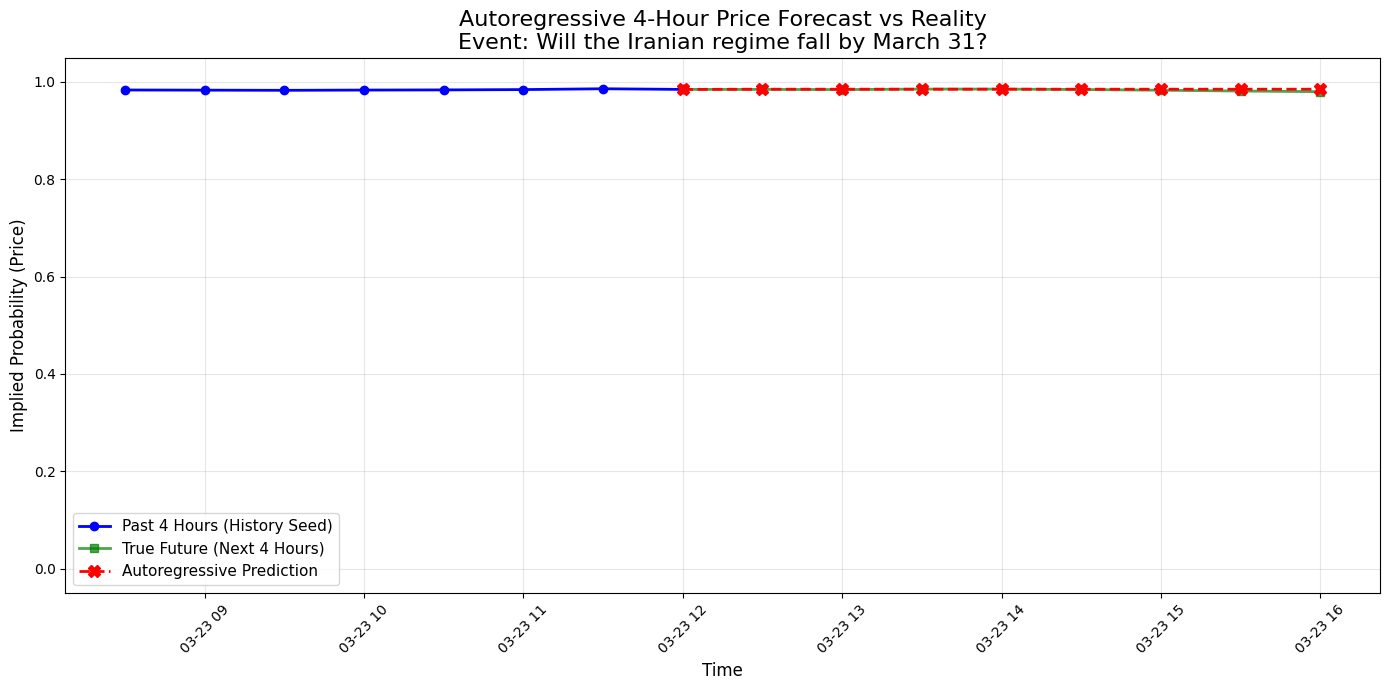

In [8]:
# 1. Select a valid event from the test set that has at least 8 remaining steps
test_df = df_ml.iloc[split_idx:].copy()
valid_events = test_df['Event_name'].value_counts()
valid_events = valid_events[valid_events >= 8].index

# Find sequences with the highest min-max deviation in their 8-step forward window for each event
event_max_deviations = []

for event in valid_events:
    event_data = test_df[test_df['Event_name'] == event].reset_index()
    max_deviation = -1
    best_start_idx = 0
    for i in range(len(event_data) - 7):  # Ensure there are 8 remaining steps
        future_window = event_data.iloc[i : i + 8]['price']
        deviation = future_window.max() - future_window.min()
        if deviation > max_deviation:
            max_deviation = deviation
            best_start_idx = i
    if max_deviation >= 0:
        event_max_deviations.append((max_deviation, event, best_start_idx))

# Sort descending and get top 5
event_max_deviations.sort(reverse=True, key=lambda x: x[0])
top_events = event_max_deviations[:5]

for rank, (dev, sample_event, best_start_idx) in enumerate(top_events, 1):
    print(f"\n{'='*50}")
    print(f"Top {rank} Event (Highest Min-Max Deviation: {dev:.4f}): {sample_event}")
    print(f"{'='*50}\n")
    
    event_test_data = test_df[test_df['Event_name'] == sample_event].reset_index()

    # 2. Extract the initial state (the seed)
    start_row = event_test_data.iloc[best_start_idx]
    start_datetime = start_row['datetime']

    current_sequence = [start_row[f'price_lag_{i}'] for i in range(window_size, 0, -1)]
    feature_row = start_row[feature_cols].copy()
    predictions = []

    # 3. Recursive Forecasting (8 steps = 4 hours)
    for step in range(8):
        pred_df_row = pd.DataFrame([feature_row], columns=feature_cols).astype(X_train.dtypes.to_dict())
        
        pred_price = float(model.predict(pred_df_row)[0])
        pred_price = float(np.clip(pred_price, 0, 1))
        predictions.append(pred_price)
        
        current_sequence.append(pred_price)
        
        for i in range(1, window_size + 1):
            feature_row[f'price_lag_{i}'] = current_sequence[-i]
            
        feature_row['rolling_mean_4h'] = np.mean(current_sequence[-window_size:])
        feature_row['rolling_std_4h'] = np.std(current_sequence[-window_size:], ddof=1)

    # 4. Gather True Data for comparision
    df_30m_event = df_30m[df_30m['Event_name'] == sample_event].reset_index(drop=True)
    start_idx_30m = df_30m_event[df_30m_event['datetime'] == start_datetime].index[0]

    history_df = df_30m_event.iloc[start_idx_30m - window_size : start_idx_30m].copy()
    future_df = df_30m_event.iloc[start_idx_30m : start_idx_30m + 8].copy()

    pred_df = future_df.copy()
    pred_df['price'] = predictions

    last_history_time = history_df['datetime'].iloc[-1]
    last_history_price = history_df['price'].iloc[-1]

    # 5. Evaluate Forecasting Metrics
    true_future_prices = future_df['price'].values
    pred_future_prices = np.array(predictions)

    ar_rmse = np.sqrt(mean_squared_error(true_future_prices, pred_future_prices))
    ar_mae = mean_absolute_error(true_future_prices, pred_future_prices)

    true_direction = np.diff([last_history_price] + list(true_future_prices)) > 0
    pred_direction = np.diff([last_history_price] + list(pred_future_prices)) > 0
    directional_accuracy = np.mean(true_direction == pred_direction) * 100

    print("=== 4-Hour Forecast Metrics ===")
    print(f"RMSE (Root Mean Squared Error): {ar_rmse:.4f}")
    print(f"MAE (Mean Absolute Error):      {ar_mae:.4f}")
    print(f"Directional Accuracy:           {directional_accuracy:.1f}%\n")

    # 6. Plotting
    plt.figure(figsize=(14, 7))

    plt.plot(history_df['datetime'], history_df['price'], label='Past 4 Hours (History Seed)', color='blue', marker='o', linewidth=2)

    true_times = [last_history_time] + future_df['datetime'].tolist()
    true_prices = [last_history_price] + future_df['price'].tolist()
    pred_prices = [last_history_price] + pred_df['price'].tolist()

    plt.plot(true_times, true_prices, label='True Future (Next 4 Hours)', color='green', linestyle='-', marker='s', linewidth=2, alpha=0.7)
    plt.plot(true_times, pred_prices, label='Autoregressive Prediction', color='red', linestyle='--', marker='X', markersize=8, linewidth=2)

    plt.title(f'Autoregressive 4-Hour Price Forecast vs Reality\nEvent: {sample_event}', fontsize=16)
    plt.xlabel('Time', fontsize=12)
    plt.ylabel('Implied Probability (Price)', fontsize=12)
    plt.ylim(-0.05, 1.05) # Reverted to normal full percentage boundaries to see full variation
    plt.grid(alpha=0.3)
    plt.legend(fontsize=11)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()